# **Modularity and Community Structure in the Zachary Karate Club Network**

**Objective:** <br>
This notebook applies spectral modularity maximisation to the Zachary Karate Club graph. The aim is to identify groups of vertices (communities) whose members are more densely connected to one another than would be expected under a degree-preserving random-network model.

The workflow is:
1. Construct and inspect the original network.
2. Build its modularity matrix.
3. Use an eigenvector of that matrix to obtain an initial bipartition.
4. Recursively split communities when the relevant leading eigenvalue is positive.
5. Examine how standard network measures behave on the original graph and on graphs retaining only within-community edges.

The notebook uses NetworkX for graph operations, NumPy for matrix and eigenvalue calculations, and Matplotlib for visualisation.

# **Constructing the Karate Club graph**

The Zachary Karate Club network is a well-known empirical social network. Each vertex represents one of the 34 club members, and an undirected edge represents a recorded friendship between two members.

For this dataset:
- n = $|V|$ = 34: number of vertices (members).
- m = $|E|$ = 78: number of edges (friendship ties).

The graph is undirected, so an edge $(i,j)$ represents a mutual connection. The sorted node list is retained so that the rows and columns of later matrices correspond consistently to the node labels.

In [61]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

G = nx.karate_club_graph()

nodes = sorted(G.nodes())
n = G.number_of_nodes()
m = G.number_of_edges()

print("Number of nodes:", n)
print("Number of edges:", m)

Number of nodes: 34
Number of edges: 78


# **Visualising the original network**
A spring layout places strongly connected vertices relatively close together while spreading the graph out for readability. The fixed random seed makes the layout reproducible across notebook runs.

At this stage all vertices have the same colour: no community assignment has yet been made. The drawing is a visual overview, not the community-detection result.

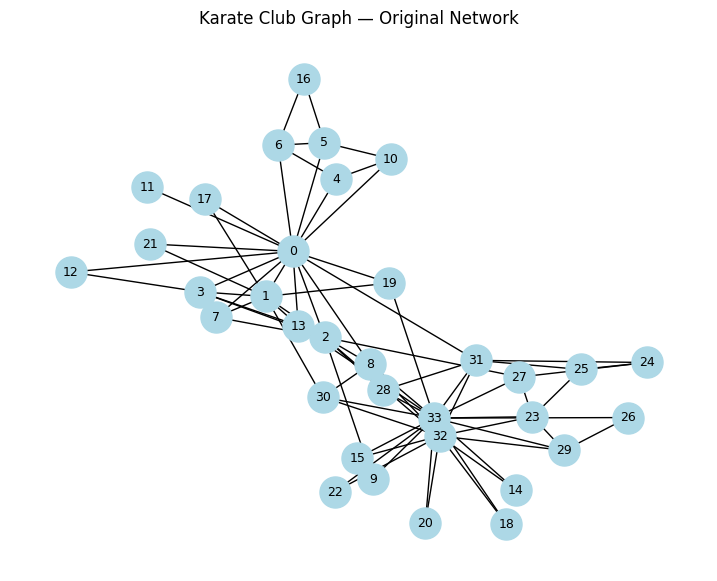

In [62]:
pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos=pos, with_labels=True,
    node_color="lightblue", node_size=500, font_size=9
)
plt.title("Karate Club Graph — Original Network")
plt.axis("off")
plt.show()

# **Constructing the modularity matrix**
Let \(A\) be the adjacency matrix of the undirected, unweighted graph:
$$A_{ij} = \begin{cases} 1, & \text{if vertices } i \text{ and } j \text{ are connected}, \\ 0, & \text{otherwise}. \end{cases}$$
The degree of vertex $i$ is
$$k_i = \sum_j A_{ij}.$$
The modularity matrix is defined by
$$\boxed{B_{ij} = A_{ij} - \frac{k_i k_j}{2m}} \qquad \text{or, in matrix form,} \qquad \boxed{B = A - \frac{kk^{\mathsf T}}{2m}}.$$

Here, $A_{ij}$ is the observed adjacency, while $\frac{k_i k_j}{2m}$ is the expected adjacency contribution under the degree-based null model. Thus, an entry of $B$ measures the difference between the observed connection and its null-model expectation.

**Implementation notes**


*   weight=None constructs the unweighted adjacency matrix, consistent with
the assignment's 34-vertex, 78-edge graph formulation.
*   np.outer(degrees, degrees) forms the matrix whose $(i,j)$ entry is $k_i k_j$.
*   Dividing by $2m$ gives the null-model term.

For an undirected graph, $B$ is symmetric. Its row sums are zero (up to floating-point precision), since $\sum_j A_{ij}=k_i$ and $\sum_j k_j=2m$. The checks below test these properties.




In [63]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
degrees = A.sum(axis=1)

B = A - np.outer(degrees, degrees) / (2 * m)

print("Adjacency matrix shape:", A.shape)
print("Modularity matrix shape:", B.shape)
print("Is B symmetric?", np.allclose(B, B.T))
print("Row sums approximately zero?", np.allclose(B.sum(axis=1), 0))

Adjacency matrix shape: (34, 34)
Modularity matrix shape: (34, 34)
Is B symmetric? True
Row sums approximately zero? True


# **Initial spectral bipartition**
For a two-way partition, assign each vertex a sign:
$$
s_i =
\begin{cases}
+1, & \text{if vertex } i \text{ belongs to group 1},\\
-1, & \text{if vertex } i \text{ belongs to group 2}.
\end{cases}
$$

The modularity of this bipartition can be written as
$$Q = \frac{1}{4m}s^{\mathsf T}Bs$$

Maximising this discrete expression directly is difficult. Spectral modularity methods relax the entries of $s$ to real values and use the leading eigenvector of the symmetric modularity matrix as an approximation. By the Rayleigh–Ritz principle, the unit vector that maximises $x^{\mathsf T}Bx$ is an eigenvector associated with the largest eigenvalue of $B$.

The sign of each component of that eigenvector is then used to assign vertices to the two groups. The code uses np.linalg.eigh, which is designed for real symmetric (or complex Hermitian) matrices, and selects the eigenvector corresponding to the largest eigenvalue.

A positive leading eigenvalue indicates a direction in which a modularity-improving split is possible under this spectral criterion. The printed eigenvalue and node lists show the initial split found by the computation.


In [64]:
eigenvalues, eigenvectors = np.linalg.eigh(B)

idx = np.argmax(eigenvalues)
largest_eigenvalue = eigenvalues[idx]
leading_eigenvector = eigenvectors[:, idx]

labels = np.where(leading_eigenvector > 0, 1, -1)

community_1 = [
    nodes[i] for i in range(n) if labels[i] == 1
]
community_2 = [
    nodes[i] for i in range(n) if labels[i] == -1
]

print("Largest eigenvalue:", largest_eigenvalue)
print("Community 1:", community_1)
print("Community 2:", community_2)

Largest eigenvalue: 4.977080225729887
Community 1: [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
Community 2: [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]


# **Visualising the initial split**
The two colours represent the two groups assigned by the signs of the leading eigenvector. The node positions are kept identical to those in the original graph so that the two drawings can be compared without layout changes.

The colours indicate the algorithm's partition, not the historical club factions as independently verified ground truth.

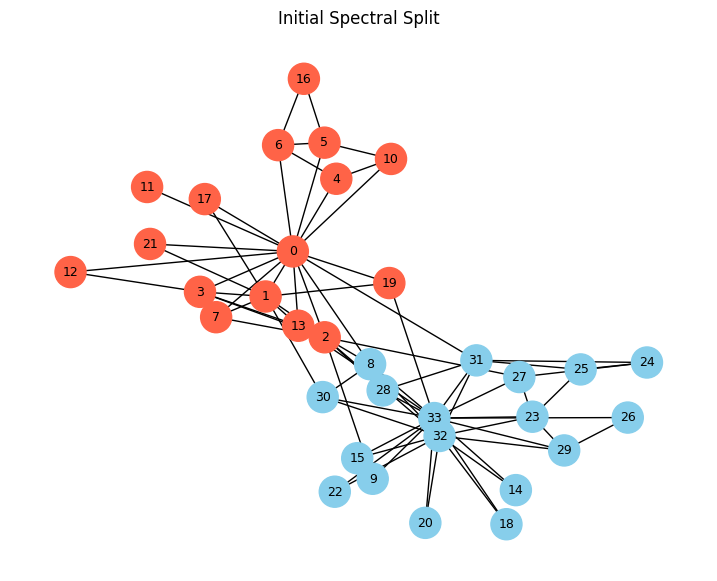

In [65]:
node_colors = [
    "tomato" if labels[i] == 1 else "skyblue"
    for i in range(n)
]

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos=pos, with_labels=True,
    node_color=node_colors, node_size=500, font_size=9
)
plt.title("Initial Spectral Split")
plt.axis("off")
plt.show()

# **Defining the community-splitting procedure**
The function get_split applies the spectral procedure to one currently identified community.

For a community $C\subseteq V$, the assignment's recursive procedure uses the corresponding block of the original graph's modularity matrix:
$$
B^{(C)} = B[C,C],
\qquad
B^{(C)}_{ij} = A_{ij} - \frac{k_i k_j}{2m},
\quad i,j \in C.
$$
The degrees $k_i,k_j$ and total edge count $m$ in this expression are those of the original graph. The function extracts a submatrix of the original $B$, it does not rebuild a new modularity matrix using degrees and edge count recalculated inside $C$.

The function then:
1. Maps the community's node labels to their positions in the original matrix.
2. Extracts the relevant rows and columns using np.ix_.
3. Computes the largest eigenvalue and its eigenvector.
4. Divides the community according to the signs of the eigenvector components.
5. Returns the eigenvalue and the two proposed groups.

In [66]:
def get_split(community, B, nodes):
    node_to_idx = {node: i for i, node in enumerate(nodes)}
    indices = [node_to_idx[node] for node in community]

    B_sub = B[np.ix_(indices, indices)]

    eigenvalues, eigenvectors = np.linalg.eigh(B_sub)
    idx = np.argmax(eigenvalues)

    largest_eigenvalue = eigenvalues[idx]
    leading_eigenvector = eigenvectors[:, idx]

    group_1 = [
        community[i]
        for i in range(len(community))
        if leading_eigenvector[i] > 0
    ]

    group_2 = [
        community[i]
        for i in range(len(community))
        if leading_eigenvector[i] <= 0
    ]

    return largest_eigenvalue, group_1, group_2

# **Recursive spectral partitioning**
The algorithm begins with one community containing all vertices. At each iteration it examines the current communities and attempts to split one of them.

For a community $C$, let $\,$ $\lambda_1^{(C)}$ be the largest eigenvalue of its restricted modularity matrix. The stopping rule used here is:
$$
\lambda_1^{(C)} \leq 0
\quad \Longrightarrow \quad
\text{do not split } C.
$$

If the leading eigenvalue is positive and the eigenvector produces two non-empty groups, the community is replaced by those two groups. The updated partition is copied into history.

The loop stops when a complete pass through the current communities finds no further valid split. The output reports the eigenvalue associated with each accepted split, the number of communities after that split, and the final number of communities.

In this run, the algorithm records four successful splits, producing five final communities.

In [67]:
communities = [nodes.copy()]
history = [[community.copy() for community in communities]]

split_number = 0

while True:
    split_found = False

    for i, community in enumerate(communities):
        eigenvalue, group_1, group_2 = get_split(
            community, B, nodes
        )

        if eigenvalue <= 0:
            continue

        if not group_1 or not group_2:
            continue

        communities[i:i+1] = [group_1, group_2]

        split_number += 1
        history.append([
            group.copy() for group in communities
        ])

        print(
            f"Split {split_number}: "
            f"eigenvalue = {eigenvalue:.4f}, "
            f"communities = {len(communities)}"
        )

        split_found = True
        break

    if not split_found:
        break

print("\nTotal successful splits:", split_number)
print("Final number of communities:", len(communities))

Split 1: eigenvalue = 4.9771, communities = 2
Split 2: eigenvalue = 2.9441, communities = 3
Split 3: eigenvalue = 2.1480, communities = 4
Split 4: eigenvalue = 2.5041, communities = 5

Total successful splits: 4
Final number of communities: 5


# **Visualising every partition snapshot**
Each panel shows the same original graph and the same fixed node positions, but vertices are coloured according to their community membership at that stage.

Using a fixed layout makes changes in colour easier to compare: the geometry does not move between panels. The number of colours increases as recursive splitting proceeds.

The edges are still all the edges of the original graph in these panels. Therefore, edges connecting different coloured communities remain visible; the colours show the partition rather than an edge-pruned graph.

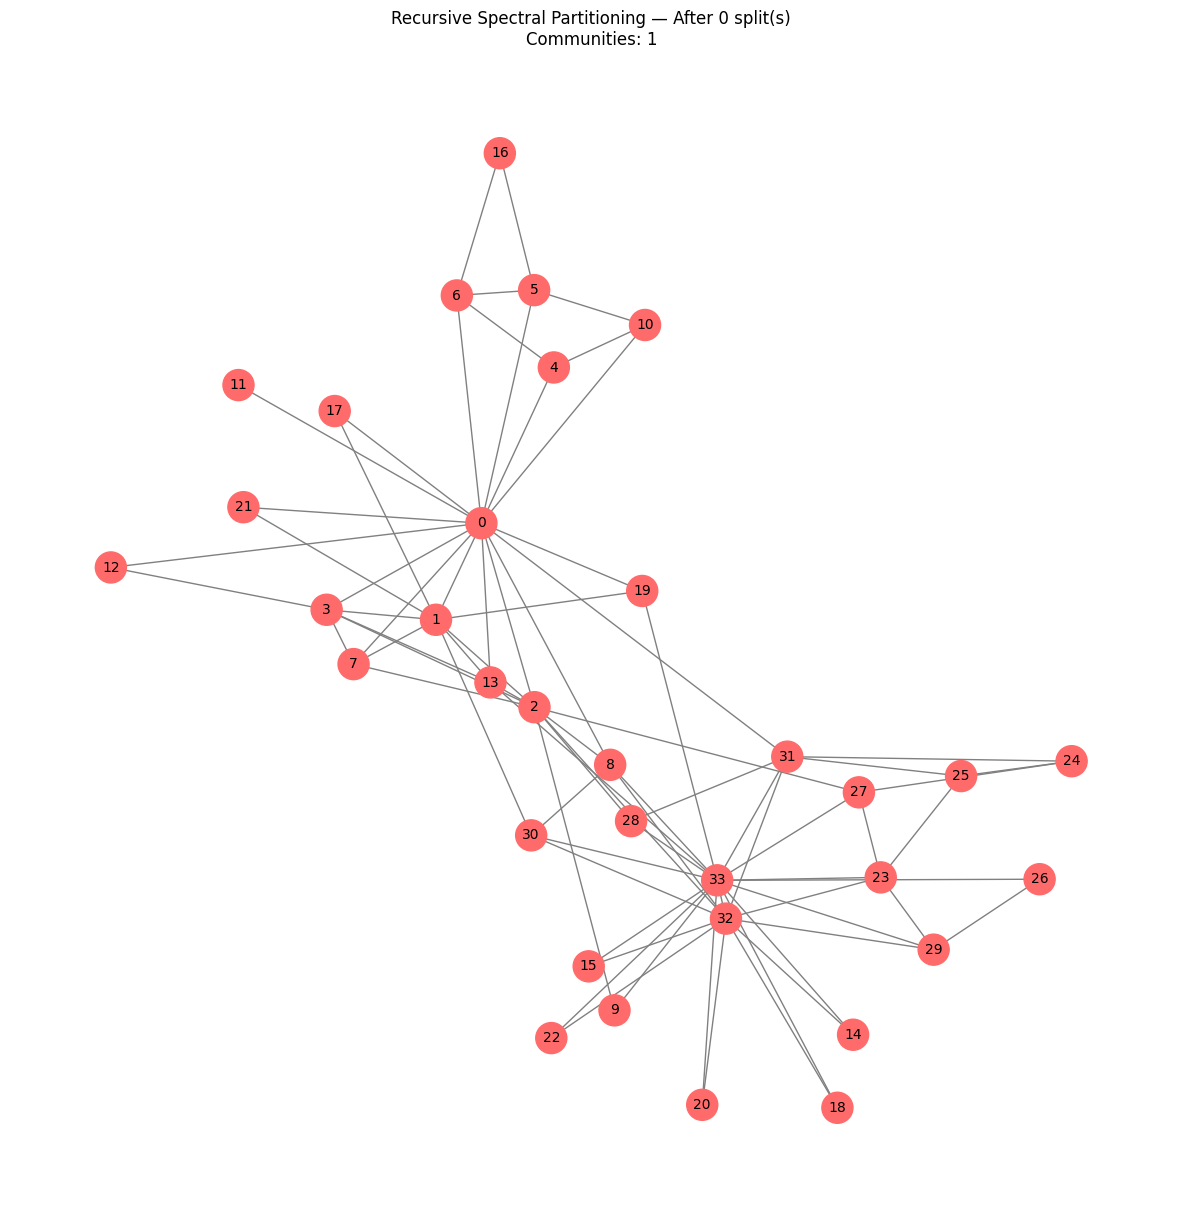

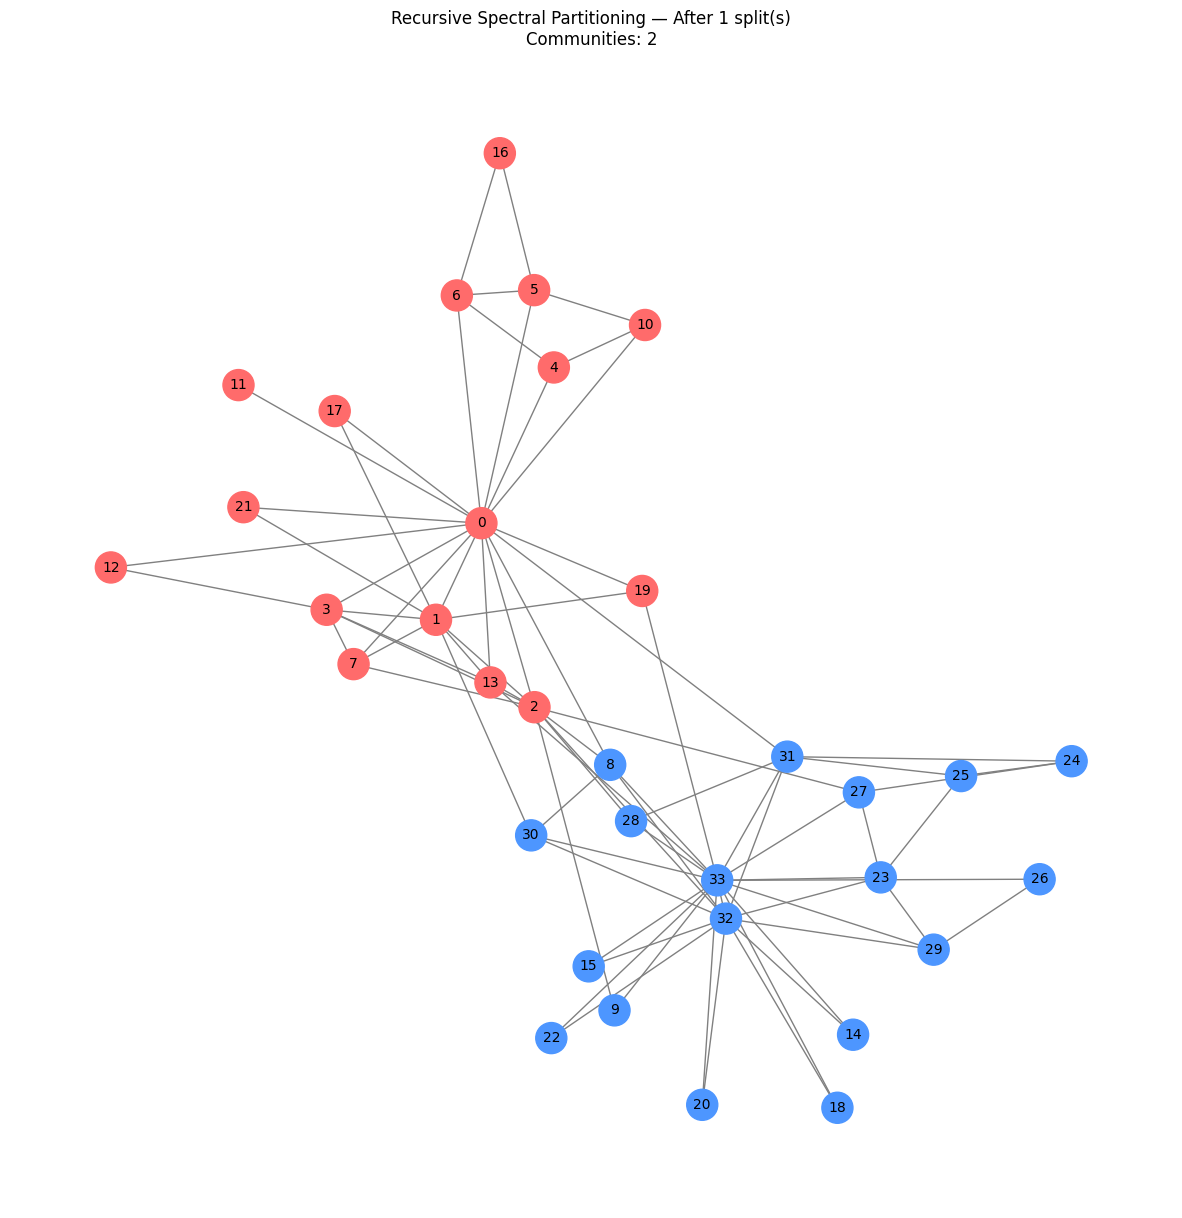

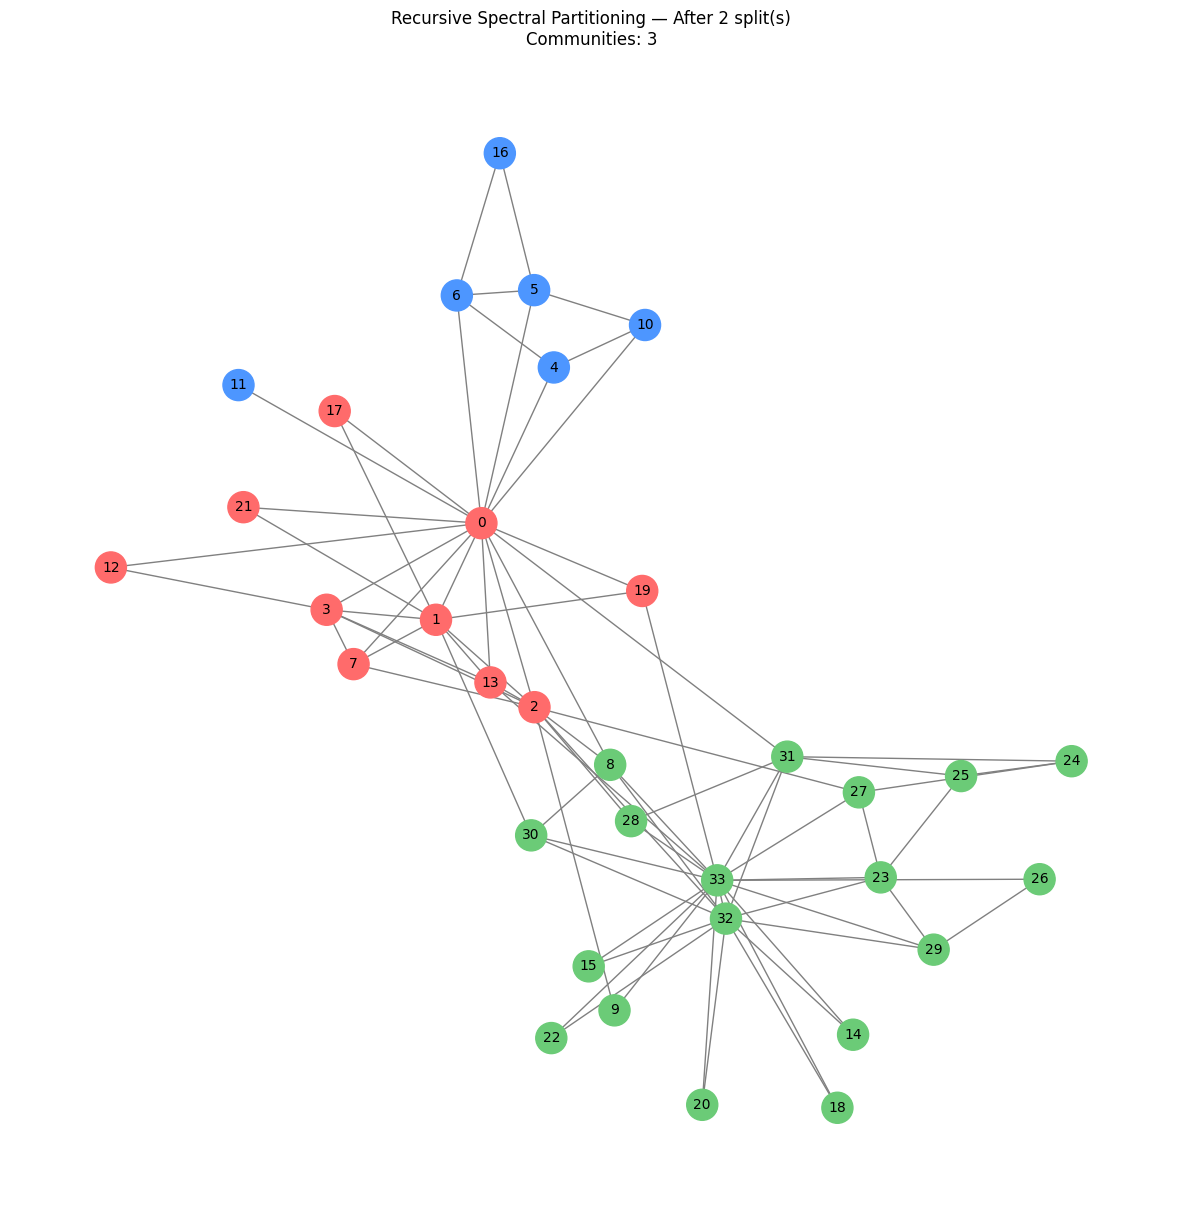

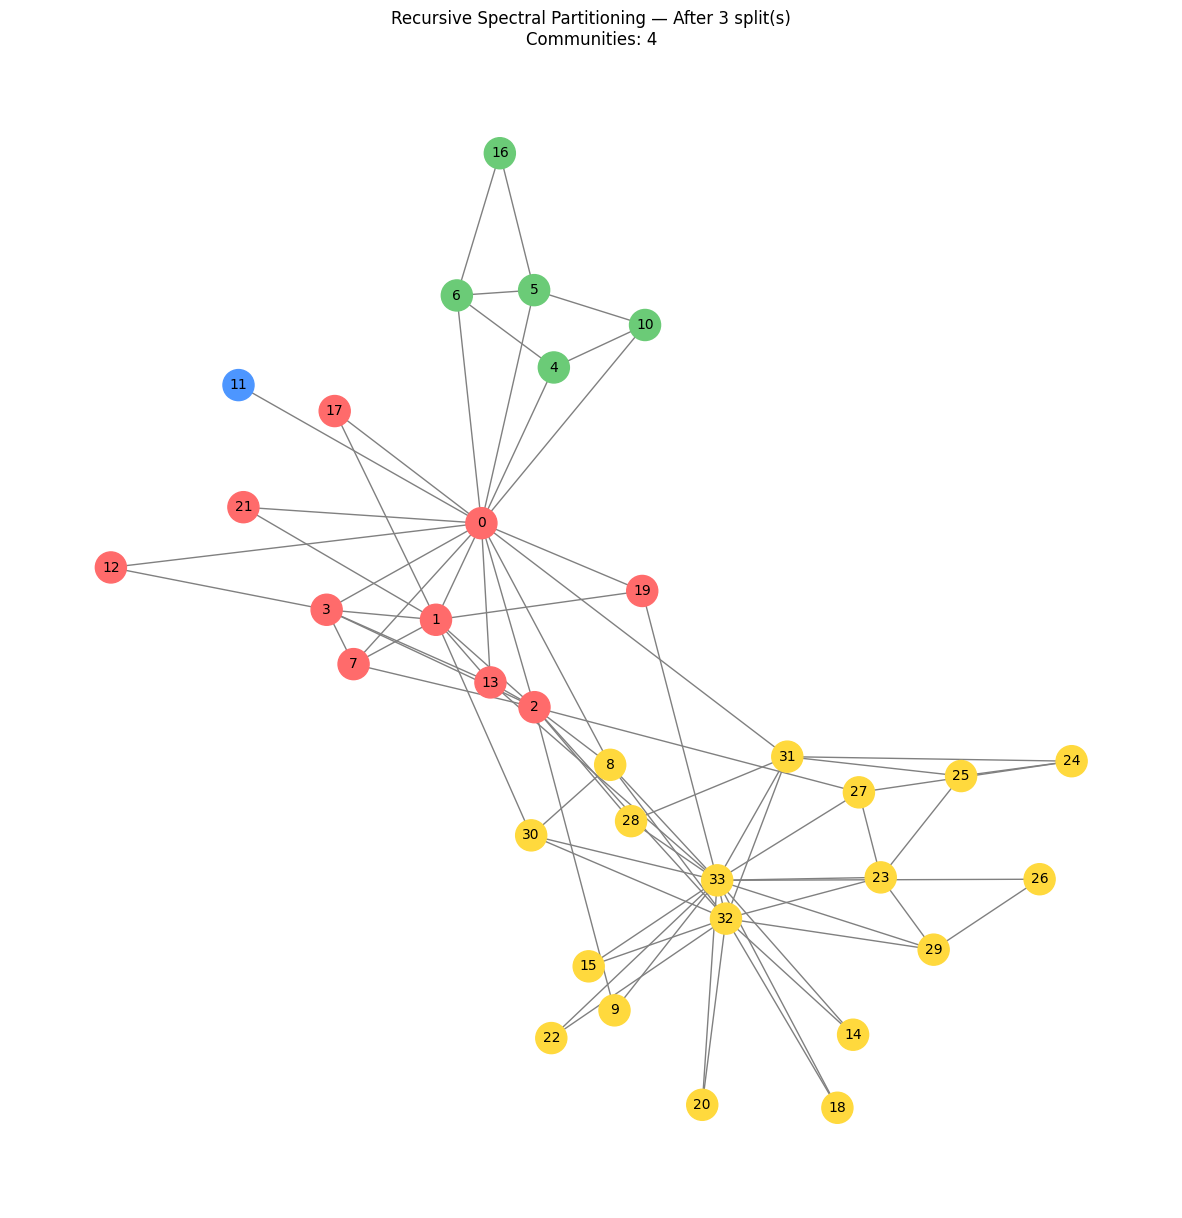

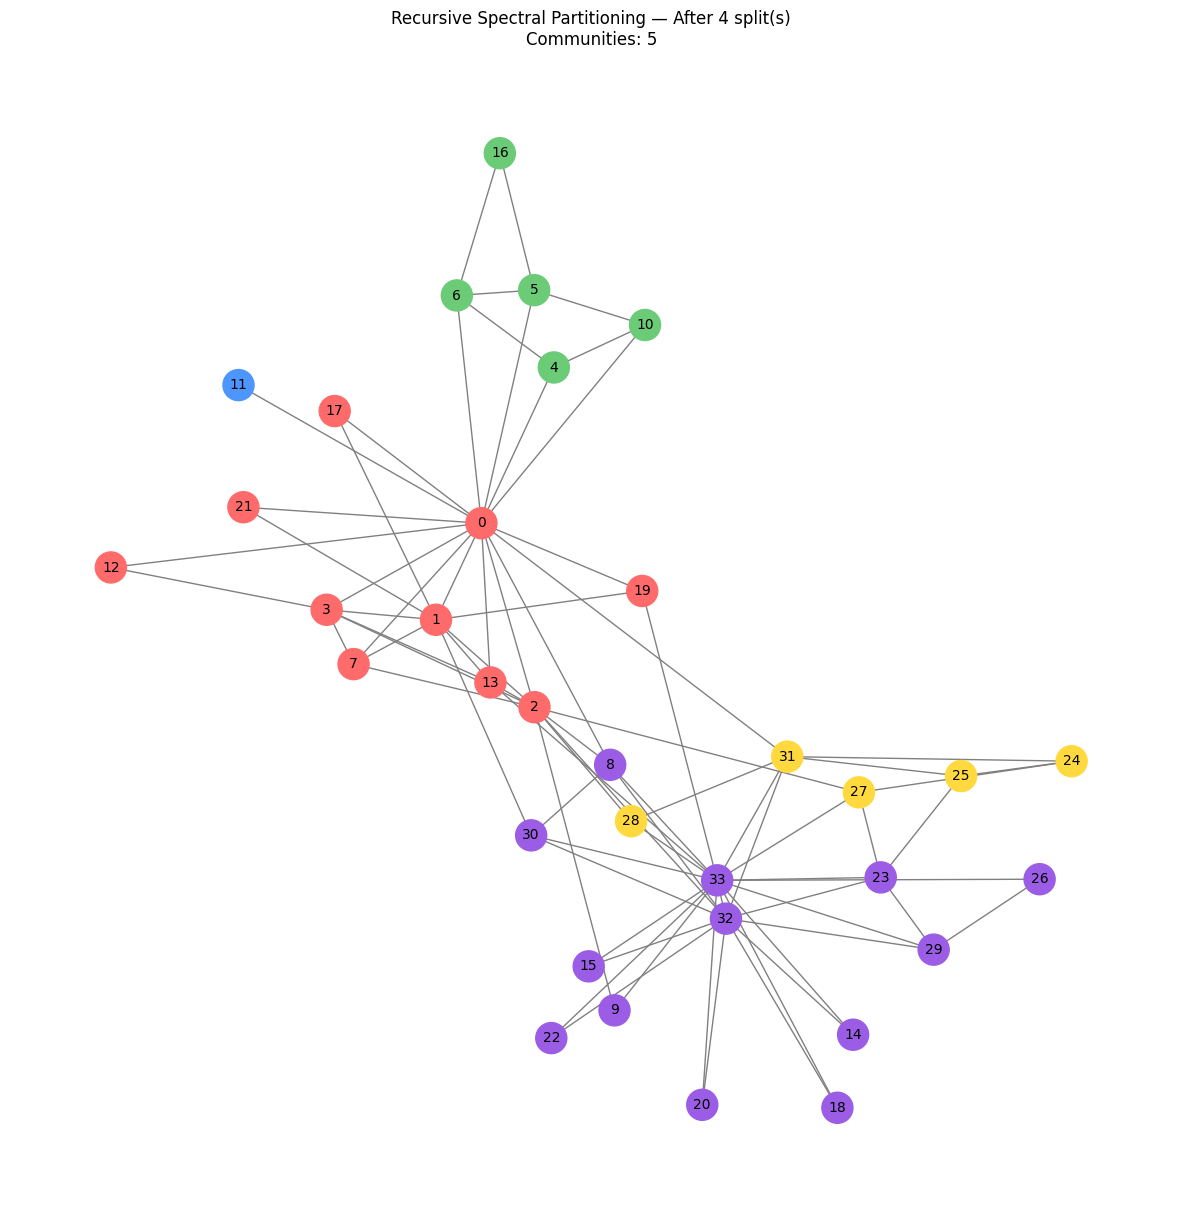

In [68]:
# Custom colour palette
palette = [
    "#FF6B6B",  # Coral red
    "#4D96FF",  # Blue
    "#6BCB77",  # Green
    "#FFD93D",  # Yellow
    "#9B5DE5",  # Purple
    "#F15BB5",  # Pink
    "#00BBF9",  # Cyan
    "#F4A261"   # Orange
]

for step, communities_at_step in enumerate(history):

    colors = palette[:len(communities_at_step)]

    node_colors = {}

    for i, community in enumerate(communities_at_step):
        for node in community:
            node_colors[node] = colors[i]

    plt.figure(figsize=(15, 15))

    nx.draw_networkx(
        G,
        pos=pos,
        with_labels=True,
        node_color=[node_colors[node] for node in G.nodes()],
        node_size=500,
        font_size=10,
        edge_color="gray"
    )

    plt.title(
        f"Recursive Spectral Partitioning — "
        f"After {step} split(s)\n"
        f"Communities: {len(communities_at_step)}"
    )
    plt.axis("off")
    plt.show()

# **Centrality and local clustering on the original graph**
The assignment asks for four network measures:

**Degree centrality:**
$$
C_D(i)=\frac{k_i}{n-1}.
$$

It measures the fraction of all other vertices directly connected to vertex $i$.

**Betweenness centrality:**
$$
C_B(i)=
\sum_{s\ne i\ne t}
\frac{\sigma_{st}(i)}{\sigma_{st}},
$$

where $\sigma_{st}$ is the number of shortest paths from $s$ to $t$, and $\sigma_{st}(i)$ is the number of those paths that pass through $i$. It captures a vertex's role in shortest-path communication.

**Closeness centrality:**
$$
C_C(i)=\frac{n-1}{\sum_{j\ne i}d(i,j)},
$$

where $d(i,j)$ is the shortest-path distance between vertices $i$ and $j$. It reflects how near a vertex is, on average, to the rest of the network.

**Clustering coefficient:**
$$
C(i)=\frac{2T(i)}{k_i(k_i-1)},
$$

where $T(i)$ is the number of edges among the neighbours of $i$. It measures how interconnected a vertex's immediate neighbours are.

In [69]:
# Calculate metrics on the original graph
degree_original = nx.degree_centrality(G)
betweenness_original = nx.betweenness_centrality(G)
closeness_original = nx.closeness_centrality(G)
clustering_original = nx.clustering(G)

node=0

print("Metrics for node", node)
print("Degree centrality:", degree_original[node])
print("Betweenness centrality:", betweenness_original[node])
print("Closeness centrality:", closeness_original[node])
print("Clustering coefficient:", clustering_original[node])

Metrics for node 0
Degree centrality: 0.48484848484848486
Betweenness centrality: 0.43763528138528146
Closeness centrality: 0.5689655172413793
Clustering coefficient: 0.15


# **Recording original-network metrics at each partition stage**
This cell stores the four centrality measures for every node at every entry in history.

The graph passed to each NetworkX function is still G, the unchanged original graph. Community membership changes between snapshots, but the edges of G do not. Consequently, these original-network metric values are expected to remain identical across all five snapshots. Repeating the calculation makes the comparison explicit, but it does not make the metrics partition-dependent.

In [70]:

# Store the four metrics at every split
metrics_history = {
    "degree": [],
    "betweenness": [],
    "closeness": [],
    "clustering": []
}

for step, communities_at_step in enumerate(history):

    # Degree centrality
    degree = nx.degree_centrality(G)

    # Betweenness centrality
    betweenness = nx.betweenness_centrality(G)

    # Closeness centrality
    closeness = nx.closeness_centrality(G)

    # Clustering coefficient
    clustering = nx.clustering(G)

    metrics_history["degree"].append(degree)
    metrics_history["betweenness"].append(betweenness)
    metrics_history["closeness"].append(closeness)
    metrics_history["clustering"].append(clustering)

print("Metrics calculated for", len(metrics_history["degree"]), "snapshots.")


Metrics calculated for 5 snapshots.


# **Original-network metrics for node 0**
The output lists node 0's four measures at each recorded partition stage. Since all calculations use the same original graph $G$, the values should be constant.

This is a useful distinction for interpreting the assignment's request to examine metric evolution: a partition alone does not alter a graph's centralities. To study the effect of separating communities on connectivity, the next section defines a second, explicitly modified graph for each snapshot.

In [71]:

node=0

print("Original-network metrics for node", node)
for step in range(len(history)):
    print(
        f"After {step} split(s): "
        f"Degree = {metrics_history['degree'][step][node]:.4f}, "
        f"Betweenness = {metrics_history['betweenness'][step][node]:.4f}, "
        f"Closeness = {metrics_history['closeness'][step][node]:.4f}, "
        f"Clustering = {metrics_history['clustering'][step][node]:.4f}"
    )


Original-network metrics for node 0
After 0 split(s): Degree = 0.4848, Betweenness = 0.4376, Closeness = 0.5690, Clustering = 0.1500
After 1 split(s): Degree = 0.4848, Betweenness = 0.4376, Closeness = 0.5690, Clustering = 0.1500
After 2 split(s): Degree = 0.4848, Betweenness = 0.4376, Closeness = 0.5690, Clustering = 0.1500
After 3 split(s): Degree = 0.4848, Betweenness = 0.4376, Closeness = 0.5690, Clustering = 0.1500
After 4 split(s): Degree = 0.4848, Betweenness = 0.4376, Closeness = 0.5690, Clustering = 0.1500


# **Additional analysis: metrics after removing between-community edges**
To examine how the network measures change when communities are separated, this section constructs a modified graph $H$ for each partition snapshot.

For a given snapshot, all 34 vertices are retained, but an original edge $(u,v)$ is included in $H$ only when $u$ and $v$ belong to the same community:


$$
E(H)=\{(u,v)\in E(G):
\operatorname{community}(u)=\operatorname{community}(v)\}.
$$


Thus, edges between different communities are removed, while within-community edges are preserved. The four metrics are then calculated on this modified graph and stored in within_metrics.

In [72]:

# Store metrics after removing edges between communities
within_metrics = {
    "degree": [],
    "betweenness": [],
    "closeness": [],
    "clustering": []
}

for communities_at_step in history:

    # Assign each node to its community
    community_of = {}
    for community_id, community in enumerate(communities_at_step):
        for node in community:
            community_of[node] = community_id

    # Keep all nodes, but retain only within-community edges
    H = nx.Graph()
    H.add_nodes_from(G.nodes())

    for u, v in G.edges():
        if community_of[u] == community_of[v]:
            H.add_edge(u, v)

    # Calculate metrics on this modified graph
    within_metrics["degree"].append(nx.degree_centrality(H))
    within_metrics["betweenness"].append(
        nx.betweenness_centrality(H)
    )
    within_metrics["closeness"].append(
        nx.closeness_centrality(H)
    )
    within_metrics["clustering"].append(nx.clustering(H))

print("Within-community metrics calculated for",
      len(history), "snapshots.")


Within-community metrics calculated for 5 snapshots.


# **Plotting the within-community metric trajectories**
For each metric, the code plots one line per vertex across the five snapshots (zero through four successful splits). The horizontal axis is the number of successful splits; the vertical axis is the selected metric.

These plots are based on within_metrics, so changes reflect the removal of edges that connect different communities. They are not plots of the original graph's unchanged centralities.

Each line follows one node across the partition stages. The plots allow us to see whether a node's relative structural position changes as the network is separated into increasingly fine communities.

Within-Community Metrics — Additional Analysis.



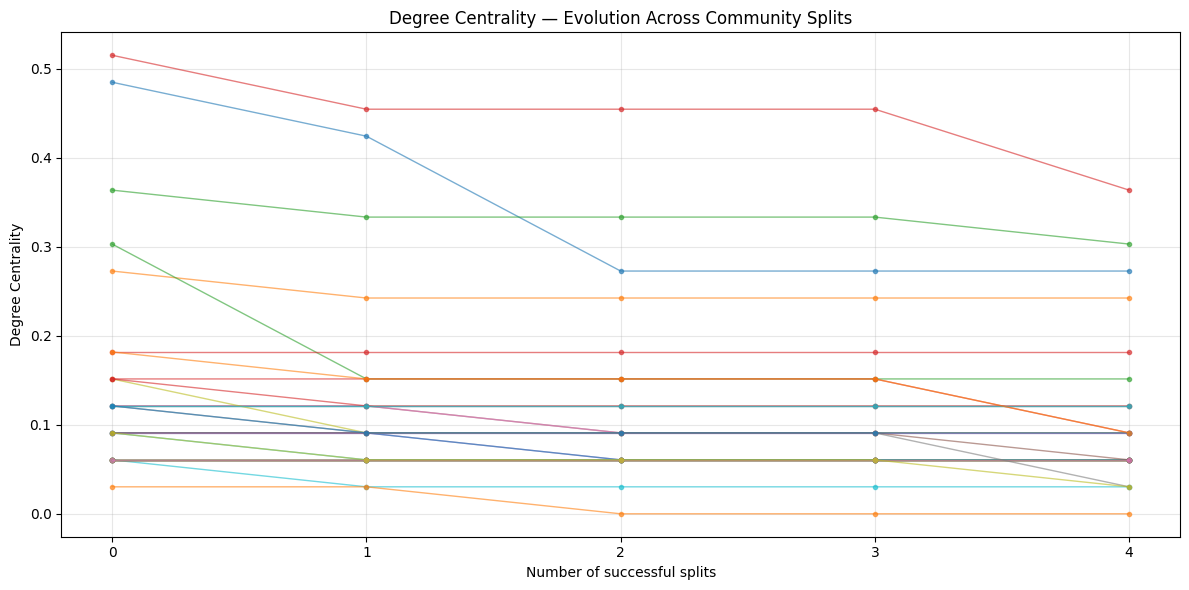

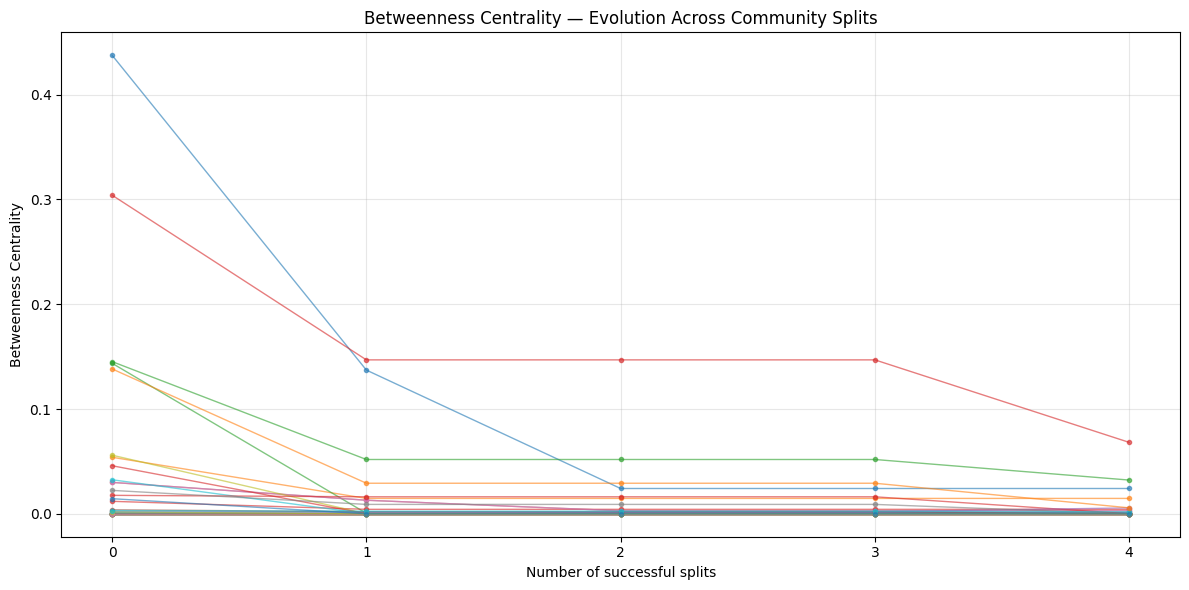

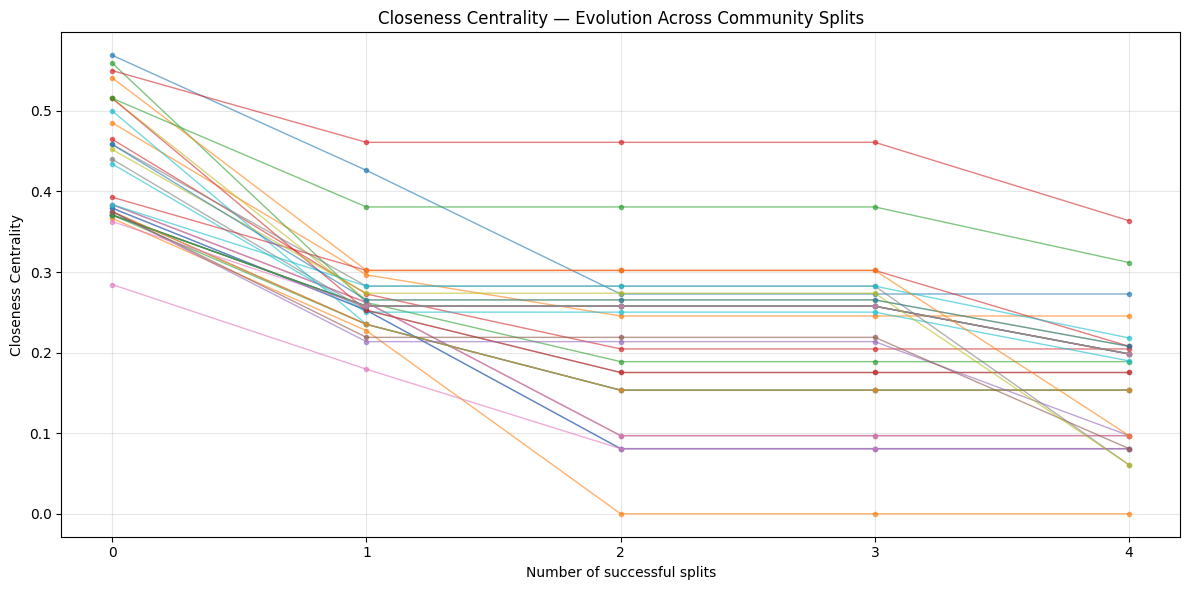

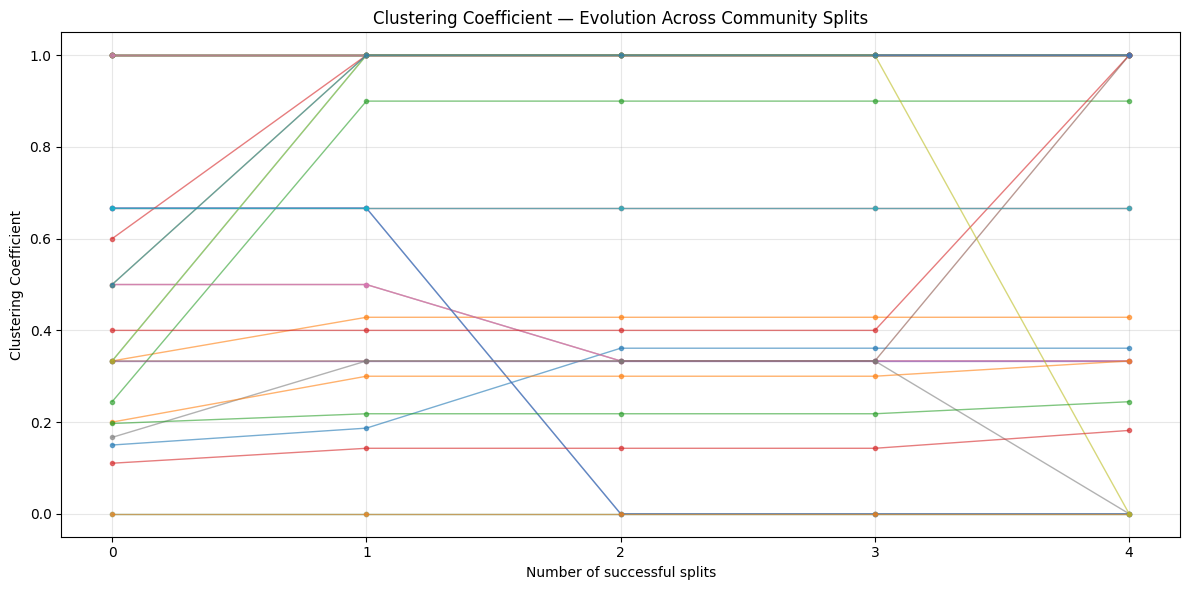

In [73]:
print("Within-Community Metrics — Additional Analysis.\n")
metric_names = {
    "degree": "Degree Centrality",
    "betweenness": "Betweenness Centrality",
    "closeness": "Closeness Centrality",
    "clustering": "Clustering Coefficient"
}

steps = range(len(history))

for metric, title in metric_names.items():
    plt.figure(figsize=(12, 6))

    for node in nodes:
        values = [
            snapshot[node] for snapshot in within_metrics[metric]
        ]
        plt.plot(steps, values, marker="o",
                 markersize=3, linewidth=1, alpha=0.6)

    plt.xlabel("Number of successful splits")
    plt.ylabel(title)
    plt.title(title + " — Evolution Across Community Splits")
    plt.xticks(list(steps))
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# **Identifying the highest-ranked nodes after the final split**
This cell ranks vertices by degree, betweenness, and closeness centrality in the final within-community graph (the snapshot after four successful splits).

The top-five lists provide a compact way to identify vertices that remain prominent after between-community edges have been removed. A high value has a metric-specific meaning: degree concerns direct neighbours, betweenness concerns shortest paths, and closeness concerns distances to reachable vertices.

The clustering coefficient is examined separately below because a value of 1.0 indicates a fully interconnected neighbourhood, not necessarily high overall centrality.

In [74]:

final_metrics = within_metrics

for metric in ["degree", "betweenness", "closeness"]:
    final_values = final_metrics[metric][-1]
    top_nodes = sorted(
        final_values.items(),
        key=lambda item: item[1],
        reverse=True
    )[:5]

    print("\nTop 5 nodes —", metric.capitalize())
    for node, value in top_nodes:
        print(f"Node {node}: {value:.4f}")



Top 5 nodes — Degree
Node 33: 0.3636
Node 32: 0.3030
Node 0: 0.2727
Node 1: 0.2424
Node 3: 0.1818

Top 5 nodes — Betweenness
Node 33: 0.0682
Node 32: 0.0322
Node 0: 0.0241
Node 1: 0.0147
Node 24: 0.0057

Top 5 nodes — Closeness
Node 33: 0.3636
Node 32: 0.3117
Node 0: 0.2727
Node 1: 0.2455
Node 29: 0.2182


# **Comparing the first and final within-community snapshots**
The below cell prints the five highest-ranked nodes for each metric in the original snapshot (zero splits) and final snapshot (four splits).

This comparison makes it possible to distinguish nodes that are prominent in the original network from those that remain prominent after between-community edges are removed. The top-five lists are descriptive summaries of the computed values; they do not by themselves establish why a node has a particular role.

In [75]:

for metric in ["degree", "betweenness", "closeness", "clustering"]:
    print("\n", metric.upper())

    for step in [0, len(history) - 1]:
        values = within_metrics[metric][step]
        top_nodes = sorted(
            values.items(),
            key=lambda item: item[1],
            reverse=True
        )[:5]

        print(f"After {step} splits:")
        print([(node, round(value, 4))
               for node, value in top_nodes])



 DEGREE
After 0 splits:
[(33, 0.5152), (0, 0.4848), (32, 0.3636), (2, 0.303), (1, 0.2727)]
After 4 splits:
[(33, 0.3636), (32, 0.303), (0, 0.2727), (1, 0.2424), (3, 0.1818)]

 BETWEENNESS
After 0 splits:
[(0, 0.4376), (33, 0.3041), (32, 0.1452), (2, 0.1437), (31, 0.1383)]
After 4 splits:
[(33, 0.0682), (32, 0.0322), (0, 0.0241), (1, 0.0147), (24, 0.0057)]

 CLOSENESS
After 0 splits:
[(0, 0.569), (2, 0.5593), (33, 0.55), (31, 0.541), (8, 0.5156)]
After 4 splits:
[(33, 0.3636), (32, 0.3117), (0, 0.2727), (1, 0.2455), (29, 0.2182)]

 CLUSTERING
After 0 splits:
[(7, 1.0), (12, 1.0), (14, 1.0), (15, 1.0), (16, 1.0)]
After 4 splits:
[(7, 1.0), (8, 1.0), (12, 1.0), (13, 1.0), (14, 1.0)]


# **Checking that the partitions are valid**
Before interpreting the results, each snapshot is checked to ensure that it is a valid partition of the original vertex set.

For every snapshot, the assertions verify that:
1. Exactly 34 node entries are present when all communities are flattened.
2. No node appears more than once.
3. The set of nodes is exactly the original graph's node set.


A PASS message for each snapshot confirms that every vertex belongs to exactly one community at that stage. These checks validate the bookkeeping of the partition; they do not independently prove that the partition is optimal.

In [76]:

# Verify that every snapshot partitions all 34 nodes exactly once
for step, communities_at_step in enumerate(history):
    flattened = [
        node
        for community in communities_at_step
        for node in community
    ]

    assert len(flattened) == 34
    assert len(set(flattened)) == 34
    assert set(flattened) == set(G.nodes())

    print(
        f"Snapshot {step}: "
        f"{len(communities_at_step)} communities — PASS"
    )


Snapshot 0: 1 communities — PASS
Snapshot 1: 2 communities — PASS
Snapshot 2: 3 communities — PASS
Snapshot 3: 4 communities — PASS
Snapshot 4: 5 communities — PASS


# **Original-network metric trajectories**
These plots use metrics_history, which stores measurements calculated on the unchanged original graph \(G\) at each partition stage.

The lines are therefore expected to be horizontal: changing the community labels does not change the original graph's adjacency structure. This is not a plotting error. It contrasts with the preceding within-community plots, where between-community edges are removed before recalculating the measures.

Together, the two sets of plots distinguish community assignment on the original graph from centrality on a graph modified to contain only within-community edges.

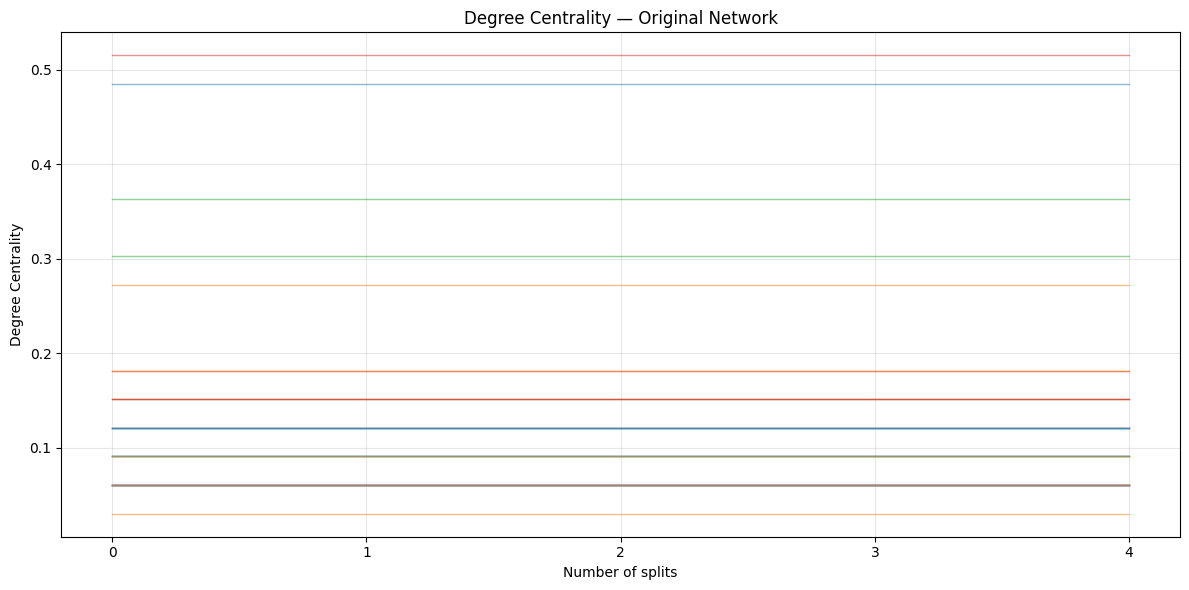

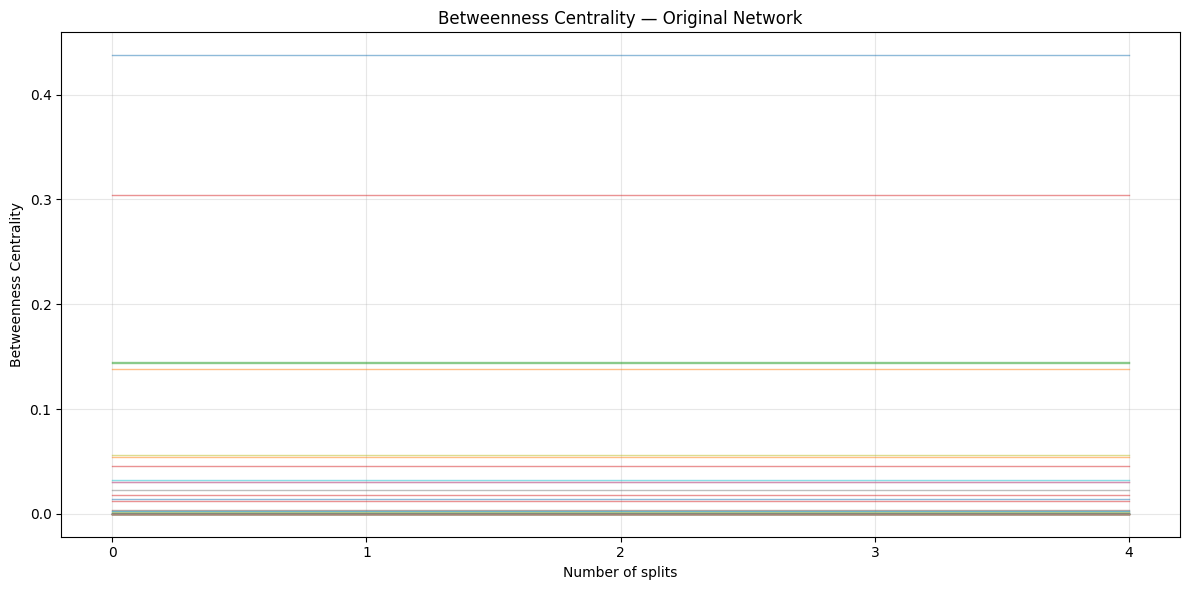

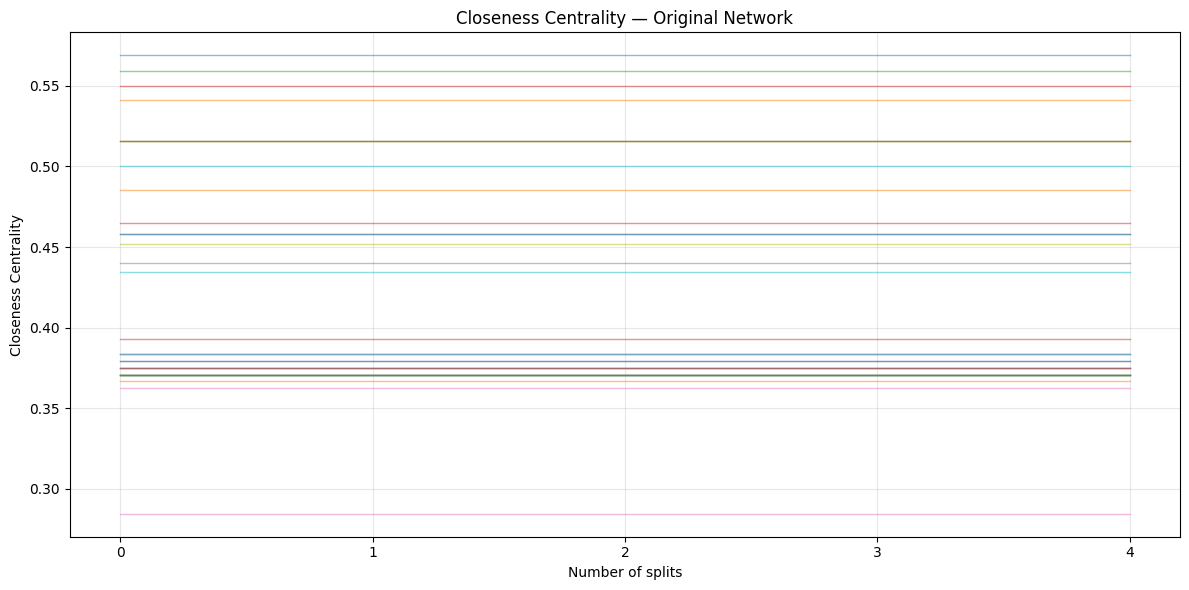

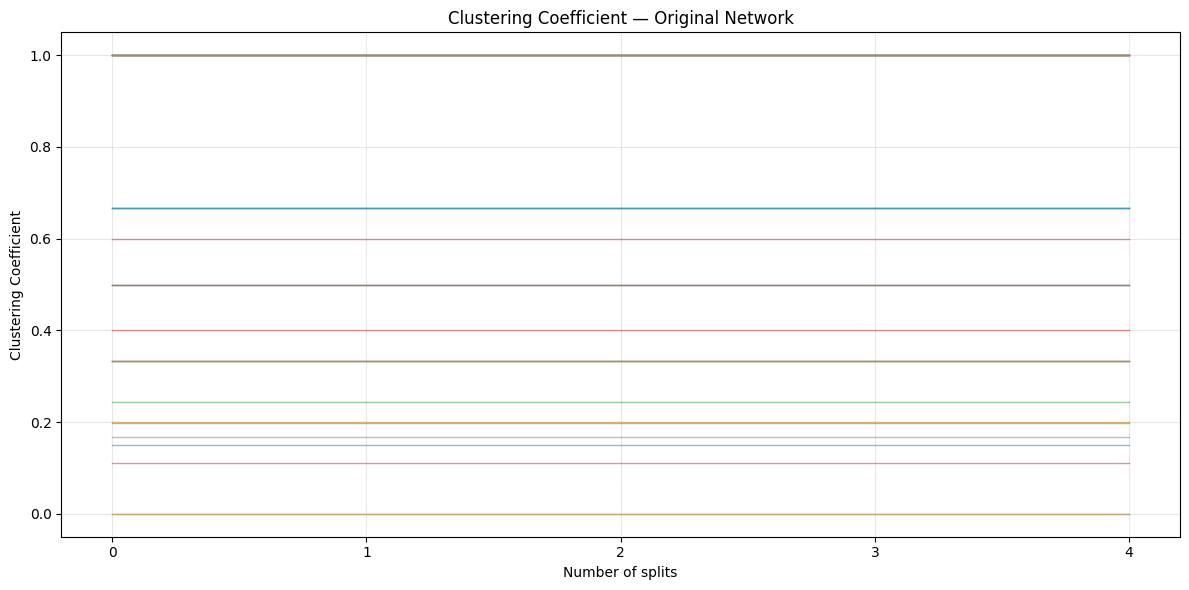

In [77]:

metric_names = {
    "degree": "Degree Centrality",
    "betweenness": "Betweenness Centrality",
    "closeness": "Closeness Centrality",
    "clustering": "Clustering Coefficient"
}

steps = list(range(len(history)))

for metric, title in metric_names.items():
    plt.figure(figsize=(12, 6))

    for node in nodes:
        values = [
            snapshot[node]
            for snapshot in metrics_history[metric]
        ]
        plt.plot(steps, values, linewidth=1, alpha=0.5)

    plt.xlabel("Number of splits")
    plt.ylabel(title)
    plt.title(title + " — Original Network")
    plt.xticks(steps)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# **Discussion: Influence of Community Structure on Centrality Metrics**

Recursive spectral modularity partitioning divides the Karate Club graph into increasingly smaller communities by identifying groups of nodes with stronger internal connections relative to the network's modularity structure.

**Degree centrality:** Initially, node 33 has the highest degree centrality (0.5152), followed by node 0 (0.4848). After four splits, node 33 remains the highest-ranked node, with a degree centrality of 0.3636. The reduction in degree centrality reflects the removal of edges connecting nodes in different communities.

**Betweenness centrality:** Node 0 initially has the highest betweenness centrality (0.4376), suggesting that it plays an important role in connecting different parts of the original network. After four splits, node 33 has the highest value (0.0682). The overall reduction in betweenness centrality indicates that removing inter-community edges changes shortest paths and reduces the bridging roles of several nodes.

**Closeness centrality:** Node 0 initially has the highest closeness centrality (0.5690), whereas node 33 ranks first after four splits (0.3636). This change illustrates how removing inter-community connections affects the distances between nodes. Because the resulting graph may be disconnected, closeness values must be interpreted with this limitation in mind.

**Clustering coefficient:** Several nodes have a clustering coefficient of 1.0 in both the initial and final networks. This means that all neighbours of each such node are connected to one another. These nodes occupy locally cohesive neighbourhoods, although a high clustering coefficient does not necessarily imply high degree, betweenness or closeness centrality.

**Conclusion:** The results show that community partitioning changes the network's connectivity and the relative importance of its nodes. Node 33 remains prominent in degree centrality and becomes the highest-ranked node in betweenness and closeness centrality after four splits. Node 0 is particularly prominent in the original network. These observations demonstrate that a node's importance depends on the structural context in which its centrality is measured.

# **Reference**

1. Newman (2006) — Keep this as your primary reference
Newman, M. E. J. (2006). Modularity and community structure in networks. Proceedings of the National Academy of Sciences, 103(23), 8577–8582.
- Supports: Modularity matrix, spectral partitioning and community detection.
- DOI: 10.1073/pnas.0601602103

2. Zachary (1977) — Original Karate Club dataset
Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. Journal of Anthropological Research, 33(4), 452–473.
- Supports: The origin and real-world interpretation of the Karate Club network.
- DOI: 10.1086/jar.33.4.3629752

3. Freeman (1977) — Centrality measures
Freeman, L. C. (1977). A set of measures of centrality based on betweenness. Sociometry, 40(1), 35–41.
- Supports: Betweenness centrality and the interpretation of nodes as bridges or intermediaries.
- DOI: 10.2307/3033543

4. Watts and Strogatz (1998) — Clustering
Watts, D. J., & Strogatz, S. H. (1998). Collective dynamics of 'small-world' networks. Nature, 393, 440–442.
- Supports: Clustering and local connectivity in networks.
- DOI: 10.1038/30918